In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Project settings
TARGET = "critical_temp"
RANDOM_STATE = 42

os.makedirs("outputs", exist_ok=True)

# Load data independently in this notebook
train_df = pd.read_csv("data/train.csv")
formula_df = pd.read_csv("data/unique_m.csv")

print("=" * 55)
print("MODEL TRAINING — DATA VALIDATION")
print("=" * 55)

print("Training dataset shape:", train_df.shape)
print("Formula dataset shape:", formula_df.shape)
print("Number of features:", train_df.shape[1] - 1)

# Check required columns
assert TARGET in train_df.columns, "Target column is missing."
assert TARGET in formula_df.columns, "Formula target is missing."
assert "material" in formula_df.columns, "Material column is missing."

# Check missing and infinite values
numeric_df = train_df.select_dtypes(include=np.number)

print("Missing values:", train_df.isna().sum().sum())
print("Infinite numerical values:", np.isinf(numeric_df.to_numpy()).sum())
print("Exact duplicate rows:", train_df.duplicated().sum())

# Verify file alignment
assert len(train_df) == len(formula_df), "Dataset row counts differ."

assert np.allclose(
    train_df[TARGET].to_numpy(),
    formula_df[TARGET].to_numpy(),
    equal_nan=True
), "Target values do not align between files."

assert train_df[TARGET].notna().all(), "Missing target values found."
assert np.isfinite(numeric_df.to_numpy()).all(), "Infinite values found."

print("Target alignment: PASS")
print("Data validation: PASS")

print("\nTarget statistics:")
print(train_df[TARGET].describe().round(3))


MODEL TRAINING — DATA VALIDATION
Training dataset shape: (21263, 82)
Formula dataset shape: (21263, 88)
Number of features: 81
Missing values: 0
Infinite numerical values: 0
Exact duplicate rows: 66
Target alignment: PASS
Data validation: PASS

Target statistics:
count    21263.000
mean        34.421
std         34.254
min          0.000
25%          5.365
50%         20.000
75%         63.000
max        185.000
Name: critical_temp, dtype: float64


In [2]:

# ============================================================
# STEP 2: FORMULA-AWARE DATA SPLITTING
# ============================================================

from sklearn.model_selection import GroupShuffleSplit

TARGET = "critical_temp"
RANDOM_STATE = 42

# Input features and target
X = train_df.drop(columns=[TARGET]).copy()
y = train_df[TARGET].copy()

# Group using the material labels from unique_m.csv
groups = formula_df["material"].astype(str).to_numpy()

# First split: 85% development data, 15% test data
splitter_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=RANDOM_STATE
)

dev_idx, test_idx = next(
    splitter_1.split(X, y, groups=groups)
)

X_dev = X.iloc[dev_idx]
y_dev = y.iloc[dev_idx]
groups_dev = groups[dev_idx]

X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

# Second split: divide development data into train and validation
splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1764705882,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    splitter_2.split(
        X_dev,
        y_dev,
        groups=groups_dev
    )
)

X_train = X_dev.iloc[train_idx]
y_train = y_dev.iloc[train_idx]

X_val = X_dev.iloc[val_idx]
y_val = y_dev.iloc[val_idx]

# Verify no material labels overlap
train_groups = set(groups[X_train.index.to_numpy()])
val_groups = set(groups[X_val.index.to_numpy()])
test_groups = set(groups[X_test.index.to_numpy()])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Display split summary
print("=" * 60)
print("FORMULA-AWARE DATA SPLIT")
print("=" * 60)

print(f"Training:   {len(X_train):,} rows ({len(X_train)/len(X):.2%})")
print(f"Validation: {len(X_val):,} rows ({len(X_val)/len(X):.2%})")
print(f"Testing:    {len(X_test):,} rows ({len(X_test)/len(X):.2%})")

print("\nUnique material labels:")
print("Training:", len(train_groups))
print("Validation:", len(val_groups))
print("Testing:", len(test_groups))

print("\nMaterial label overlap:")
print("Train-validation:", len(train_groups & val_groups))
print("Train-test:", len(train_groups & test_groups))
print("Validation-test:", len(val_groups & test_groups))

print("\nData split completed.")


FORMULA-AWARE DATA SPLIT
Training:   14,895 rows (70.05%)
Validation: 3,160 rows (14.86%)
Testing:    3,208 rows (15.09%)

Unique material labels:
Training: 10878
Validation: 2332
Testing: 2332

Material label overlap:
Train-validation: 0
Train-test: 0
Validation-test: 0

Data split completed.


In [3]:

# ============================================================
# STEP 3: EXTRA TREES REGRESSOR — MODEL TRAINING
# ============================================================

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Initialize the baseline Extra Trees model
model = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

# Train using training data only
model.fit(X_train, y_train)

print("=" * 60)
print("EXTRA TREES MODEL TRAINING COMPLETED")
print("=" * 60)

print("Model:", type(model).__name__)
print("Number of trees:", model.n_estimators)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# Generate predictions for training and validation
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

# Evaluation helper
def evaluate_regression(actual, predicted):
    return {
        "MAE (K)": mean_absolute_error(actual, predicted),
        "RMSE (K)": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

# Evaluate training and validation performance
training_metrics = evaluate_regression(y_train, train_pred)
validation_metrics = evaluate_regression(y_val, val_pred)

training_validation_results = pd.DataFrame([
    {"Dataset": "Training", **training_metrics},
    {"Dataset": "Validation", **validation_metrics}
])

print("\nTRAINING VS VALIDATION RESULTS")
display(training_validation_results.round(4))

# Check generalization gap
rmse_gap = (
    validation_metrics["RMSE (K)"]
    - training_metrics["RMSE (K)"]
)

print(f"\nTraining-validation RMSE gap: {rmse_gap:.4f} K")

training_validation_results.to_csv(
    "outputs/formula_aware_training_validation.csv",
    index=False
)

print("\nTraining and validation results saved.")
print("The test set has not been evaluated yet.")


EXTRA TREES MODEL TRAINING COMPLETED
Model: ExtraTreesRegressor
Number of trees: 200
Training samples: 14895
Validation samples: 3160
Test samples: 3208

TRAINING VS VALIDATION RESULTS


,Dataset,MAE (K),RMSE (K),R2
0,Training,1.3881,4.2694,0.9846
1,Validation,4.9828,8.8542,0.9312



Training-validation RMSE gap: 4.5848 K

Training and validation results saved.
The test set has not been evaluated yet.


In [4]:

# ============================================================
# STEP 4: FINAL TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict on the untouched test set
test_pred = model.predict(X_test)

# Calculate final test metrics
test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred)

print("=" * 60)
print("EXTRA TREES — FORMULA-AWARE TEST RESULTS")
print("=" * 60)

print(f"Test MAE:  {test_mae:.4f} K")
print(f"Test RMSE: {test_rmse:.4f} K")
print(f"Test R2:   {test_r2:.4f}")

# Save the results separately from the previous baseline
final_results = pd.DataFrame([{
    "Model": "Extra Trees Regressor",
    "Evaluation": "Formula-aware split",
    "Test MAE (K)": test_mae,
    "Test RMSE (K)": test_rmse,
    "Test R2": test_r2
}])

final_results.to_csv(
    "outputs/extra_trees_formula_aware_test_results.csv",
    index=False
)

# Save predictions for further analysis
predictions = pd.DataFrame({
    "Actual (K)": y_test.to_numpy(),
    "Predicted (K)": test_pred,
    "Residual (K)": y_test.to_numpy() - test_pred
})

predictions.to_csv(
    "outputs/extra_trees_formula_aware_test_predictions.csv",
    index=False
)

print("\nTest results and predictions saved.")


EXTRA TREES — FORMULA-AWARE TEST RESULTS
Test MAE:  5.0872 K
Test RMSE: 9.9442 K
Test R2:   0.9154

Test results and predictions saved.


In [5]:

import joblib

joblib.dump(
    model,
    "outputs/extra_trees_formula_aware_model.joblib"
)

print("Formula-aware Extra Trees model saved successfully.")


Formula-aware Extra Trees model saved successfully.


In [6]:

# ============================================================
# STEP 5: SAVED MODEL VERIFICATION
# ============================================================

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MODEL_PATH = "outputs/extra_trees_formula_aware_model.joblib"

# 1. Reload the saved model from disk
verified_model = joblib.load(MODEL_PATH)

print("=" * 65)
print("SAVED EXTRA TREES MODEL VERIFICATION")
print("=" * 65)

print("Model loaded:", type(verified_model).__name__)

# 2. Verify model type
assert type(verified_model).__name__ == "ExtraTreesRegressor", (
    "Unexpected model type."
)

# 3. Verify feature count and order
expected_features = list(X_train.columns)

if hasattr(verified_model, "feature_names_in_"):
    saved_features = list(verified_model.feature_names_in_)
    assert saved_features == expected_features, (
        "Feature names or order do not match."
    )

assert X_test.shape[1] == verified_model.n_features_in_, (
    "Test feature count does not match the saved model."
)

print("Feature count:", X_test.shape[1])
print("Feature order: PASS")

# 4. Verify saved model reproduces trained model predictions
original_predictions = model.predict(X_test)
reloaded_predictions = verified_model.predict(X_test)

predictions_match = np.allclose(
    original_predictions,
    reloaded_predictions,
    rtol=1e-7,
    atol=1e-8
)

assert predictions_match, (
    "Saved model predictions differ from the original model."
)

print("Saved-model prediction consistency: PASS")

# 5. Evaluate the reloaded model on the held-out test set
mae = mean_absolute_error(y_test, reloaded_predictions)
rmse = np.sqrt(mean_squared_error(y_test, reloaded_predictions))
r2 = r2_score(y_test, reloaded_predictions)

print("\nHELD-OUT TEST PERFORMANCE")
print(f"MAE:  {mae:.4f} K")
print(f"RMSE: {rmse:.4f} K")
print(f"R2:   {r2:.4f}")

# 6. Inspect 10 held-out test samples
sample_size = min(10, len(X_test))
sample_positions = np.random.default_rng(42).choice(
    len(X_test),
    size=sample_size,
    replace=False
)

sample_X = X_test.iloc[sample_positions]
sample_actual = y_test.iloc[sample_positions].to_numpy()
sample_predicted = verified_model.predict(sample_X)

sample_results = pd.DataFrame({
    "Actual Critical Temp (K)": sample_actual,
    "Predicted Critical Temp (K)": sample_predicted,
    "Absolute Error (K)": np.abs(sample_actual - sample_predicted)
})

print("\nSAMPLE PREDICTION CHECK")
display(sample_results.round(4))

# 7. Save verification results
sample_results.to_csv(
    "outputs/extra_trees_verification_samples.csv",
    index=False
)

verification_summary = pd.DataFrame([{
    "Model": type(verified_model).__name__,
    "Feature Count": X_test.shape[1],
    "Predictions Match Saved Model": predictions_match,
    "Test MAE (K)": mae,
    "Test RMSE (K)": rmse,
    "Test R2": r2
}])

verification_summary.to_csv(
    "outputs/extra_trees_verification_summary.csv",
    index=False
)

print("\nVERIFICATION CHECKS PASSED")
print("Saved verification summary and sample predictions.")


SAVED EXTRA TREES MODEL VERIFICATION
Model loaded: ExtraTreesRegressor
Feature count: 81
Feature order: PASS
Saved-model prediction consistency: PASS

HELD-OUT TEST PERFORMANCE
MAE:  5.0872 K
RMSE: 9.9442 K
R2:   0.9154

SAMPLE PREDICTION CHECK


,Actual Critical Temp (K),Predicted Critical Temp (K),Absolute Error (K)
0,15.000,12.8319,2.1681
1,0.264,0.3186,0.0546
2,75.000,68.7920,6.2080
3,11.200,11.7932,0.5932
4,42.000,39.1697,2.8303
5,31.700,16.8108,14.8892
6,3.200,7.3959,4.1959
7,19.800,23.7666,3.9666
8,23.000,24.9285,1.9285
9,8.600,7.4792,1.1208



VERIFICATION CHECKS PASSED
Saved verification summary and sample predictions.


10 LARGEST TEST PREDICTION ERRORS


,Actual (K),Predicted (K),Residual (K),Absolute Error (K)
3102,185.0,7.0836,177.9164,177.9164
3017,120.0,5.3828,114.6172,114.6172
2059,91.0,2.2621,88.7379,88.7379
106,30.0,94.9559,-64.9559,64.9559
4,13.0,74.6592,-61.6592,61.6592
1586,30.3,89.5454,-59.2454,59.2454
1330,34.7,91.8865,-57.1865,57.1865
978,35.0,91.8865,-56.8865,56.8865
1488,80.0,26.8813,53.1187,53.1187
3101,60.0,7.0836,52.9164,52.9164


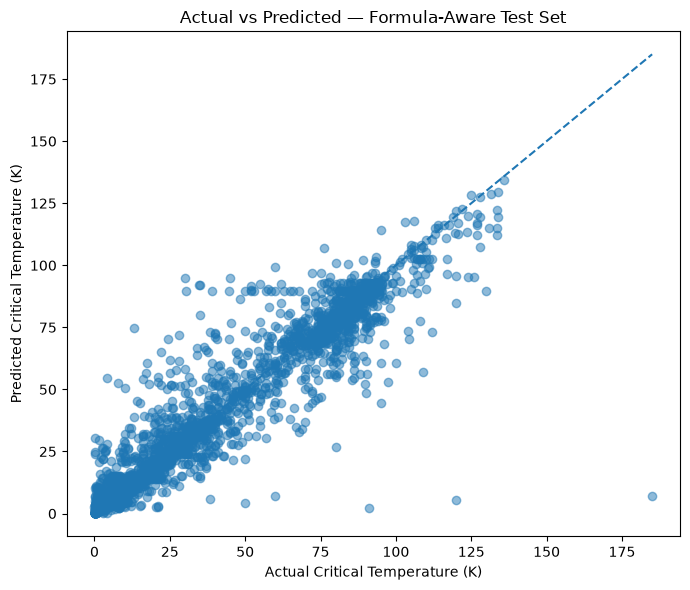

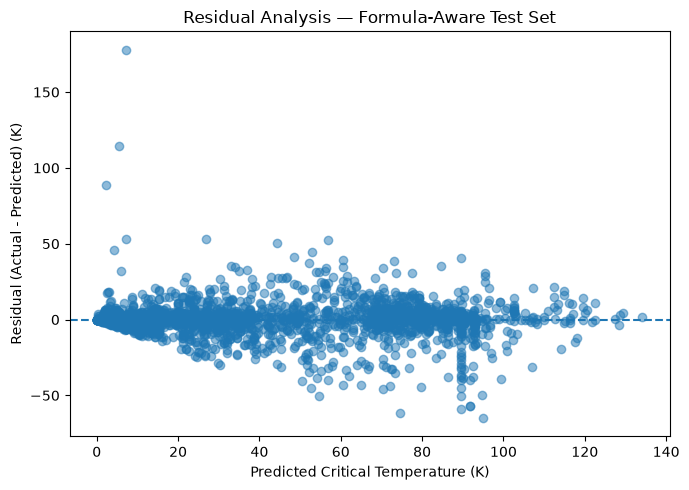

Error analysis saved.


In [7]:

# ============================================================
# STEP 6: PREDICTION ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use predictions from the reloaded, verified model
verified_pred = verified_model.predict(X_test)
actual = y_test.to_numpy()
residuals = actual - verified_pred

error_df = pd.DataFrame({
    "Actual (K)": actual,
    "Predicted (K)": verified_pred,
    "Residual (K)": residuals,
    "Absolute Error (K)": np.abs(residuals)
})

# Show the 10 largest prediction errors
print("10 LARGEST TEST PREDICTION ERRORS")
display(
    error_df.sort_values(
        "Absolute Error (K)",
        ascending=False
    ).head(10).round(4)
)

# Actual vs predicted
plt.figure(figsize=(7, 6))
plt.scatter(actual, verified_pred, alpha=0.5)

lower = min(actual.min(), verified_pred.min())
upper = max(actual.max(), verified_pred.max())

plt.plot([lower, upper], [lower, upper], "--")
plt.xlabel("Actual Critical Temperature (K)")
plt.ylabel("Predicted Critical Temperature (K)")
plt.title("Actual vs Predicted — Formula-Aware Test Set")
plt.tight_layout()
plt.show()

# Residuals vs predicted
plt.figure(figsize=(7, 5))
plt.scatter(verified_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Critical Temperature (K)")
plt.ylabel("Residual (Actual - Predicted) (K)")
plt.title("Residual Analysis — Formula-Aware Test Set")
plt.tight_layout()
plt.show()

# Save error analysis
error_df.to_csv(
    "outputs/extra_trees_formula_aware_error_analysis.csv",
    index=False
)

print("Error analysis saved.")


In [9]:

# ============================================================
# STEP 7: INVESTIGATE THE LARGEST TEST ERRORS
# ============================================================

# Keep the original test row indices
error_details = error_df.copy()

error_details["Row_Index"] = X_test.index.to_numpy()
error_details["Material"] = (
    formula_df.loc[X_test.index, "material"].to_numpy()
)

# Show the 15 largest absolute errors
worst_errors = error_details.sort_values(
    "Absolute Error (K)",
    ascending=False
).head(15)

print("15 LARGEST TEST ERRORS")
display(worst_errors.round(4))

# Show engineered feature values for the worst 5 rows
worst_indices = worst_errors["Row_Index"].head(5)

print("\nFEATURE VALUES FOR THE WORST 5 PREDICTIONS")
display(X_test.loc[worst_indices].round(4))

# Check whether those material labels have multiple target values
material_target_counts = (
    formula_df.groupby("material")["critical_temp"]
    .nunique()
)

worst_errors["Targets_for_material"] = (
    worst_errors["Material"].map(material_target_counts)
)

print("\nDO THE WORST-ERROR MATERIAL LABELS HAVE CONFLICTING TARGETS?")
display(
    worst_errors[
        ["Material", "Actual (K)", "Predicted (K)",
         "Absolute Error (K)", "Targets_for_material"]
    ].round(4)
)

# Save detailed investigation
worst_errors.to_csv(
    "outputs/extra_trees_worst_error_investigation.csv",
    index=False
)

print("\nWorst-error investigation saved.")


15 LARGEST TEST ERRORS


,Actual (K),Predicted (K),Residual (K),Absolute Error (K),Row_Index,Material
3102,185.0,7.0836,177.9164,177.9164,20573,H2S1
3017,120.0,5.3828,114.6172,114.6172,20064,H1W1O3
2059,91.0,2.2621,88.7379,88.7379,13677,Na0.05W1O3
106,30.0,94.9559,-64.9559,64.9559,684,Bi2.2Sr2Ca1.8Cu3O
4,13.0,74.6592,-61.6592,61.6592,46,Gd0.4Ba0.6Cu1O3
1586,30.3,89.5454,-59.2454,59.2454,10520,Y1Ba2Cu3O7
1330,34.7,91.8865,-57.1865,57.1865,8646,Hg0.85Re0.15Ba2Cu1O4.58
978,35.0,91.8865,-56.8865,56.8865,6481,Hg0.85Re0.15Ba2Cu1O4.58
1488,80.0,26.8813,53.1187,53.1187,9826,Tb1Sr2Cu2.7Mo0.3O7
3101,60.0,7.0836,52.9164,52.9164,20572,H2S1



FEATURE VALUES FOR THE WORST 5 PREDICTIONS


,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,mean_Valence,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence
20573,2,16.5365,11.3603,5.6850,3.1937,0.1364,0.2246,31.0571,10.0164,15.5285,...,3.50,2.6667,2.4495,1.8171,0.4101,0.5623,5,1.3333,2.5000,2.3570
20064,3,66.9491,46.5692,14.3657,14.9981,0.3091,0.5357,182.8321,36.5664,82.8806,...,3.00,2.6000,2.2894,2.1689,0.8487,0.9110,5,1.0000,2.1602,1.7436
13677,3,74.2764,57.5278,40.7405,29.3669,0.5821,0.5386,167.8406,45.1088,77.5257,...,3.00,2.9753,2.2894,2.6009,0.8487,0.7172,5,1.4691,2.1602,1.7354
684,5,83.2448,91.3775,59.5061,70.5999,1.3115,1.2605,192.9810,44.3757,67.2338,...,2.60,2.6600,2.4022,2.4467,1.5194,1.4512,3,0.9000,1.2000,1.2427
46,4,93.5306,51.3681,68.4518,32.7595,1.1681,1.3683,141.2506,6.8796,56.7637,...,2.25,2.0800,2.2134,2.0659,1.3689,1.1327,1,0.9600,0.4330,0.2713



DO THE WORST-ERROR MATERIAL LABELS HAVE CONFLICTING TARGETS?


,Material,Actual (K),Predicted (K),Absolute Error (K),Targets_for_material
3102,H2S1,185.0,7.0836,177.9164,2
3017,H1W1O3,120.0,5.3828,114.6172,1
2059,Na0.05W1O3,91.0,2.2621,88.7379,1
106,Bi2.2Sr2Ca1.8Cu3O,30.0,94.9559,64.9559,1
4,Gd0.4Ba0.6Cu1O3,13.0,74.6592,61.6592,1
1586,Y1Ba2Cu3O7,30.3,89.5454,59.2454,110
1330,Hg0.85Re0.15Ba2Cu1O4.58,34.7,91.8865,57.1865,2
978,Hg0.85Re0.15Ba2Cu1O4.58,35.0,91.8865,56.8865,2
1488,Tb1Sr2Cu2.7Mo0.3O7,80.0,26.8813,53.1187,2
3101,H2S1,60.0,7.0836,52.9164,2



Worst-error investigation saved.


In [10]:

# ============================================================
# STEP 8: EXTRA TREES HYPERPARAMETER TUNING
# Uses training and validation data only.
# Does NOT evaluate or select using the test set.
# ============================================================

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

configurations = [
    {
        "name": "Baseline",
        "n_estimators": 200,
        "max_depth": None,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },
    {
        "name": "Regularized A",
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_leaf": 2,
        "max_features": 1.0
    },
    {
        "name": "Regularized B",
        "n_estimators": 300,
        "max_depth": 20,
        "min_samples_leaf": 3,
        "max_features": 1.0
    },
    {
        "name": "Feature Subsampling",
        "n_estimators": 300,
        "max_depth": 30,
        "min_samples_leaf": 2,
        "max_features": 0.8
    },
    {
        "name": "Regularized C",
        "n_estimators": 400,
        "max_depth": 40,
        "min_samples_leaf": 2,
        "max_features": 0.9
    }
]

tuning_results = []
tuned_models = {}

for cfg in configurations:
    candidate = ExtraTreesRegressor(
        n_estimators=cfg["n_estimators"],
        max_depth=cfg["max_depth"],
        min_samples_leaf=cfg["min_samples_leaf"],
        max_features=cfg["max_features"],
        random_state=42,
        n_jobs=-1
    )

    candidate.fit(X_train, y_train)

    train_pred_candidate = candidate.predict(X_train)
    val_pred_candidate = candidate.predict(X_val)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_pred_candidate)
    )
    val_rmse = np.sqrt(
        mean_squared_error(y_val, val_pred_candidate)
    )

    tuning_results.append({
        "Configuration": cfg["name"],
        "Train MAE": mean_absolute_error(
            y_train, train_pred_candidate
        ),
        "Train RMSE": train_rmse,
        "Validation MAE": mean_absolute_error(
            y_val, val_pred_candidate
        ),
        "Validation RMSE": val_rmse,
        "Validation R2": r2_score(y_val, val_pred_candidate),
        "RMSE Gap": val_rmse - train_rmse
    })

    tuned_models[cfg["name"]] = candidate

tuning_df = (
    pd.DataFrame(tuning_results)
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
)

print("EXTRA TREES TUNING RESULTS")
display(tuning_df.round(4))

# Select based ONLY on validation RMSE
best_configuration = tuning_df.loc[0, "Configuration"]
best_model = tuned_models[best_configuration]

print("\nSelected configuration:", best_configuration)
print("Selection criterion: lowest validation RMSE")

tuning_df.to_csv(
    "outputs/extra_trees_tuning_comparison.csv",
    index=False
)

print("Tuning comparison saved.")
print("The test set has not been used in this experiment.")


EXTRA TREES TUNING RESULTS


,Configuration,Train MAE,Train RMSE,Validation MAE,Validation RMSE,Validation R2,RMSE Gap
0,Baseline,1.3881,4.2694,4.9828,8.8542,0.9312,4.5848
1,Feature Subsampling,2.2975,4.8191,5.1102,8.9924,0.9291,4.1733
2,Regularized A,2.2481,4.7742,5.1105,9.0071,0.9288,4.2329
3,Regularized C,2.2700,4.7962,5.1110,9.0204,0.9286,4.2242
4,Regularized B,3.0282,5.6553,5.2864,9.2138,0.9255,3.5585



Selected configuration: Baseline
Selection criterion: lowest validation RMSE
Tuning comparison saved.
The test set has not been used in this experiment.


In [11]:

# ============================================================
# STEP 9: FINALIZE SELECTED EXTRA TREES MODEL
# ============================================================

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Selected using validation RMSE
final_model = best_model

# Final test evaluation
final_test_pred = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_test_pred)
final_rmse = np.sqrt(
    mean_squared_error(y_test, final_test_pred)
)
final_r2 = r2_score(y_test, final_test_pred)

final_metrics = pd.DataFrame([{
    "Model": "Extra Trees Regressor",
    "Configuration": best_configuration,
    "Test MAE (K)": final_mae,
    "Test RMSE (K)": final_rmse,
    "Test R2": final_r2
}])

print("FINAL SELECTED MODEL — TEST RESULTS")
display(final_metrics.round(4))

# Save the selected model
joblib.dump(
    final_model,
    "outputs/extra_trees_final_model.joblib"
)

# Save final metrics
final_metrics.to_csv(
    "outputs/extra_trees_final_metrics.csv",
    index=False
)

# Save test predictions
pd.DataFrame({
    "Actual (K)": y_test.to_numpy(),
    "Predicted (K)": final_test_pred,
    "Absolute Error (K)": np.abs(
        y_test.to_numpy() - final_test_pred
    )
}).to_csv(
    "outputs/extra_trees_final_predictions.csv",
    index=False
)

print("\nFinal model saved:")
print("outputs/extra_trees_final_model.joblib")
print("outputs/extra_trees_final_metrics.csv")
print("outputs/extra_trees_final_predictions.csv")


FINAL SELECTED MODEL — TEST RESULTS


,Model,Configuration,Test MAE (K),Test RMSE (K),Test R2
0,Extra Trees Regressor,Baseline,5.0872,9.9442,0.9154



Final model saved:
outputs/extra_trees_final_model.joblib
outputs/extra_trees_final_metrics.csv
outputs/extra_trees_final_predictions.csv


In [12]:

# ============================================================
# FINAL PROJECT CHECK: REPRODUCIBILITY AND SAVED MODEL
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load the saved formula-aware model
model_path = "outputs/extra_trees_formula_aware_model.joblib"
assert os.path.exists(model_path), f"Model file not found: {model_path}"

final_model = joblib.load(model_path)

# Validate the test predictions
final_predictions = final_model.predict(X_test)

assert len(final_predictions) == len(y_test)
assert np.isfinite(final_predictions).all()

# Recalculate test metrics
final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)
final_r2 = r2_score(y_test, final_predictions)

# Confirm consistency with the earlier evaluation
assert np.allclose(
    final_predictions,
    test_pred,
    rtol=1e-7,
    atol=1e-8
), "Predictions differ from the earlier evaluation."

summary = pd.DataFrame([{
    "Model": type(final_model).__name__,
    "Test Samples": len(y_test),
    "Features": X_test.shape[1],
    "Test MAE (K)": final_mae,
    "Test RMSE (K)": final_rmse,
    "Test R2": final_r2,
    "Predictions Valid": True,
    "Prediction Consistency": True
}])

display(summary.round(4))

summary.to_csv(
    "outputs/final_project_verification.csv",
    index=False
)

print("Saved-model verification passed.")
print("Verification summary saved.")


,Model,Test Samples,Features,Test MAE (K),Test RMSE (K),Test R2,Predictions Valid,Prediction Consistency
0,ExtraTreesRegressor,3208,81,5.0872,9.9442,0.9154,True,True


Saved-model verification passed.
Verification summary saved.


In [13]:

# ============================================================
# FINAL INDEPENDENT TEST-SET CHECK
# ============================================================

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the saved model
verified_model = joblib.load(
    "outputs/extra_trees_formula_aware_model.joblib"
)

# Predict using the held-out test features
test_predictions = verified_model.predict(X_test)

# Basic validity checks
assert len(test_predictions) == len(y_test)
assert np.isfinite(test_predictions).all()

# Recalculate metrics independently
actual = np.asarray(y_test)
mae = mean_absolute_error(actual, test_predictions)
rmse = np.sqrt(mean_squared_error(actual, test_predictions))
r2 = r2_score(actual, test_predictions)

# Prediction-error checks
absolute_errors = np.abs(actual - test_predictions)
within_5K = np.mean(absolute_errors <= 5) * 100
within_10K = np.mean(absolute_errors <= 10) * 100

print("=" * 60)
print("FINAL HELD-OUT TEST CHECK")
print("=" * 60)
print("Model:", type(verified_model).__name__)
print("Test samples:", len(actual))
print(f"MAE: {mae:.4f} K")
print(f"RMSE: {rmse:.4f} K")
print(f"R2: {r2:.4f}")
print(f"Predictions within 5 K: {within_5K:.2f}%")
print(f"Predictions within 10 K: {within_10K:.2f}%")
print("All predictions finite:", np.isfinite(test_predictions).all())

# Inspect the 10 largest errors
test_report = pd.DataFrame({
    "Actual (K)": actual,
    "Predicted (K)": test_predictions,
    "Absolute Error (K)": absolute_errors
})

print("\n10 largest absolute errors:")
display(
    test_report.nlargest(10, "Absolute Error (K)").round(4)
)


FINAL HELD-OUT TEST CHECK
Model: ExtraTreesRegressor
Test samples: 3208
MAE: 5.0872 K
RMSE: 9.9442 K
R2: 0.9154
Predictions within 5 K: 71.48%
Predictions within 10 K: 85.29%
All predictions finite: True

10 largest absolute errors:


,Actual (K),Predicted (K),Absolute Error (K)
3102,185.0,7.0836,177.9164
3017,120.0,5.3828,114.6172
2059,91.0,2.2621,88.7379
106,30.0,94.9559,64.9559
4,13.0,74.6592,61.6592
1586,30.3,89.5454,59.2454
1330,34.7,91.8865,57.1865
978,35.0,91.8865,56.8865
1488,80.0,26.8813,53.1187
3101,60.0,7.0836,52.9164
